# HW 2: Agent-Based Modeling of Pandemic Spread

**Objective:** Develop an agent-based model to simulate epidemic spread and explore the impact of interventions, such as social distancing, on infection and recovery.

## A. Building the Base Model: Infection Dynamics in a Population

### i. Environment and initial conditions

- Create a bounded 20 × 20 grid representing an area where individuals (agents) move and interact.
- Place 200 agents at random cells, in the following states:
  - 195 susceptible (S) agents: individuals at risk of infection;
  - 5 infected (I) agents: individuals who can transmit the infection;
  - 0 recovered (R) agents: individuals who have recovered and are immune.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

SUSCEPTIBLE, INFECTED, RECOVERED = 0, 1, 2


### ii. Agent behaviors

- *Movement:* At each time step, each agent moves to a neighboring cell (up, down, left or right) or stays in place, at random (a random walk). Agents cannot leave the grid. You may also try other movement rules, e.g., a Lévy walk.
- *Transmission:* If a susceptible agent shares a cell with at least one infected agent, it becomes infected with probability $p$.
- *Recovery:* At each time step, each infected agent recovers with probability $q$ and becomes immune.

In [2]:
def move_agents(positions, states, grid_size, rng, intervention_rng,
                m=1.0, avoidance=False):
    """Choose destinations from the old positions, then move simultaneously."""
    moves = np.array([[0, 0], [1, 0], [-1, 0], [0, 1], [0, -1]])
    population = len(states)
    proposed = positions + moves[rng.integers(len(moves), size=population)]
    valid = np.all((proposed >= 0) & (proposed < grid_size), axis=1)
    proposed[~valid] = positions[~valid]

    if avoidance:
        susceptible_ids = np.flatnonzero(states == SUSCEPTIBLE)
        candidates = positions[susceptible_ids, None, :] + moves[None, :, :]
        in_bounds = np.all((candidates >= 0) & (candidates < grid_size), axis=2)
        infected_positions = positions[states == INFECTED]
        infected_cells = infected_positions[:, 0] * grid_size + infected_positions[:, 1]
        candidate_cells = candidates[:, :, 0] * grid_size + candidates[:, :, 1]
        safe = in_bounds & ~np.isin(candidate_cells, infected_cells)
        scores = intervention_rng.random(safe.shape)
        scores[~safe] = -1
        chosen = scores.argmax(axis=1)
        destinations = candidates[np.arange(len(susceptible_ids)), chosen]
        destinations[~safe.any(axis=1)] = positions[susceptible_ids[~safe.any(axis=1)]]
        proposed[susceptible_ids] = destinations

    if m < 1:
        moving = intervention_rng.random(population) < m
        proposed[~moving] = positions[~moving]
    return proposed


def simulate_sir(grid_size=20, population=200, initial_infected=5,
                 p=0.3, q=0.02, steps=300, seed=42, m=1.0, avoidance=False):
    """Simulate synchronous movement, infection, and recovery on a square grid."""
    for name, value in [("grid_size", grid_size), ("population", population),
                        ("initial_infected", initial_infected), ("steps", steps)]:
        if not isinstance(value, (int, np.integer)):
            raise ValueError(f"{name} must be an integer")
    if grid_size < 1 or population < 1 or steps < 0:
        raise ValueError("Grid size and population must be positive; steps must be nonnegative")
    if not 0 <= initial_infected <= population:
        raise ValueError("initial_infected must be between 0 and population")
    if not (0 <= p <= 1 and 0 <= q <= 1):
        raise ValueError("p and q must be between 0 and 1")

    if not 0 <= m <= 1:
        raise ValueError("m must be between 0 and 1")

    rng = np.random.default_rng(seed)
    intervention_rng = np.random.default_rng(np.random.SeedSequence(seed).spawn(1)[0])
    positions = rng.integers(0, grid_size, size=(population, 2))
    states = np.full(population, SUSCEPTIBLE, dtype=int)
    states[:initial_infected] = INFECTED

    counts = np.zeros((steps + 1, 3), dtype=int)
    counts[0] = np.bincount(states, minlength=3)

    for step in range(1, steps + 1):
        positions = move_agents(positions, states, grid_size, rng,
                                intervention_rng, m=m, avoidance=avoidance)

        susceptible = states == SUSCEPTIBLE
        infected = states == INFECTED
        recovered = states == RECOVERED

        cell_ids = positions[:, 0] * grid_size + positions[:, 1]
        infectious_cells = np.unique(cell_ids[infected])
        exposed = susceptible & np.isin(cell_ids, infectious_cells)
        new_infections = exposed & (rng.random(population) < p)
        new_recoveries = infected & (rng.random(population) < q)

        next_states = states.copy()
        next_states[new_infections] = INFECTED
        next_states[new_recoveries] = RECOVERED
        assert np.all(next_states[recovered] == RECOVERED)
        assert np.all((positions >= 0) & (positions < grid_size))
        states = next_states
        counts[step] = np.bincount(states, minlength=3)

    return counts


In [3]:
check = simulate_sir(seed=123)
assert check.shape == (301, 3)
assert np.array_equal(check[0], [195, 5, 0])
assert np.all(check.sum(axis=1) == 200)
assert np.all(check >= 0)
assert np.all(np.diff(check[:, SUSCEPTIBLE]) <= 0)
assert np.all(np.diff(check[:, RECOVERED]) >= 0)
assert np.array_equal(check, simulate_sir(seed=123))

no_transmission = simulate_sir(p=0, seed=123)
assert np.all(no_transmission[:, SUSCEPTIBLE] == 195)
no_recovery = simulate_sir(q=0, seed=123)
assert np.all(no_recovery[:, RECOVERED] == 0)
no_infection = simulate_sir(initial_infected=0, seed=123)
assert np.all(no_infection == [200, 0, 0])

one_cell = simulate_sir(grid_size=1, population=2, initial_infected=1,
                        p=1, q=1, steps=3, seed=123)
assert np.array_equal(one_cell, [[1, 1, 0], [0, 1, 1], [0, 0, 2], [0, 0, 2]])

infection_trials = [
    simulate_sir(grid_size=1, population=6, initial_infected=5,
                 p=0.3, q=0, steps=1, seed=seed)[1, SUSCEPTIBLE] == 0
    for seed in range(1000)
]
assert abs(np.mean(infection_trials) - 0.3) < 0.06
print("All base-model checks passed.")


All base-model checks passed.


### iii. Simulation

- Simulate 300 time steps, recording the number of agents in each state at each step.
- Plot the number of agents in each state over time.

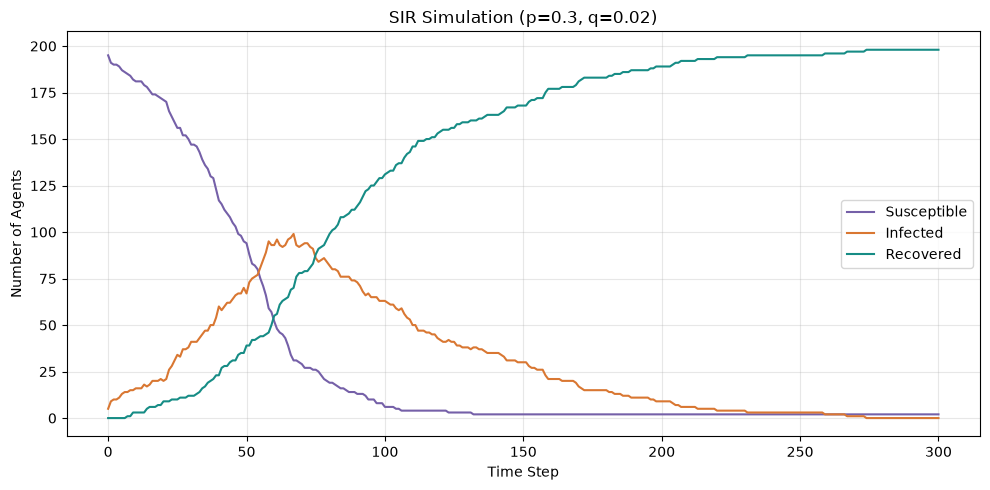

Peak infected: 99 agents at step 67
Ever infected by step 300 (including initial cases): 198
Final S, I, R: [2, 0, 198]
First step with no infected agents: 274


In [4]:
COLORS = ["#7560A8", "#D97732", "#168C85"]
LABELS = ["Susceptible", "Infected", "Recovered"]

p, q, seed = 0.3, 0.02, 42
counts = simulate_sir(p=p, q=q, seed=seed)
time = np.arange(len(counts))

fig, ax = plt.subplots(figsize=(10, 5))
for state, (label, color) in enumerate(zip(LABELS, COLORS)):
    ax.plot(time, counts[:, state], color=color, label=label)

ax.set_xlabel("Time Step")
ax.set_ylabel("Number of Agents")
ax.set_title(f"SIR Simulation (p={p}, q={q})")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/part_a_base_sir.png", dpi=200, bbox_inches="tight")
plt.show()

infected = counts[:, INFECTED]
peak_step = int(np.argmax(infected))
extinction_steps = np.flatnonzero(infected == 0)
print(f"Peak infected: {infected[peak_step]} agents at step {peak_step}")
print(f"Ever infected by step 300 (including initial cases): {200 - counts[-1, SUSCEPTIBLE]}")
print(f"Final S, I, R: {counts[-1].tolist()}")
if extinction_steps.size:
    print(f"First step with no infected agents: {extinction_steps[0]}")
else:
    print("The outbreak has not ended by step 300.")


### iv. Sensitivity analysis

- Run the simulation for all combinations of $p = 0.15, 0.3$ and $q = 0.02, 0.04$.
- For each combination, run at least 20 simulations with different random initial positions. Plot the individual runs and their average for each state over time.
- Analyze how $p$ and $q$ affect the infection peak, the time to the peak, and the total number of agents ever infected. How much do individual runs differ from the average? In how many runs does the outbreak die out early?

In [5]:
parameter_pairs = [(0.15, 0.02), (0.15, 0.04), (0.3, 0.02), (0.3, 0.04)]
n_runs = 20
steps = 300
population = 200
early_cutoff = 50
print(f"Early extinction means I reaches zero by step {early_cutoff}, inclusive.")
print("Ever infected is measured by step 300 and includes the 5 initial cases.")

sensitivity_runs = {}
sensitivity_metrics = {}
for group, (p_value, q_value) in enumerate(parameter_pairs):
    runs = np.array([
        simulate_sir(p=p_value, q=q_value, steps=steps,
                     seed=1000 + group * n_runs + run)
        for run in range(n_runs)
    ])
    assert runs.shape == (n_runs, steps + 1, 3)
    assert np.all(runs.sum(axis=2) == population)
    assert np.all(np.diff(runs[:, :, SUSCEPTIBLE], axis=1) <= 0)
    assert np.all(np.diff(runs[:, :, RECOVERED], axis=1) >= 0)

    infected_runs = runs[:, :, INFECTED]
    sensitivity_runs[(p_value, q_value)] = runs
    sensitivity_metrics[(p_value, q_value)] = {
        "peak": infected_runs.max(axis=1),
        "peak_time": infected_runs.argmax(axis=1),
        "ever_infected": population - runs[:, -1, SUSCEPTIBLE],
        "early_extinction": np.any(infected_runs[:, :early_cutoff + 1] == 0, axis=1),
        "ongoing": infected_runs[:, -1] > 0,
    }
print("Completed 80 simulations; all population checks passed.")

Early extinction means I reaches zero by step 50, inclusive.
Ever infected is measured by step 300 and includes the 5 initial cases.


Completed 80 simulations; all population checks passed.


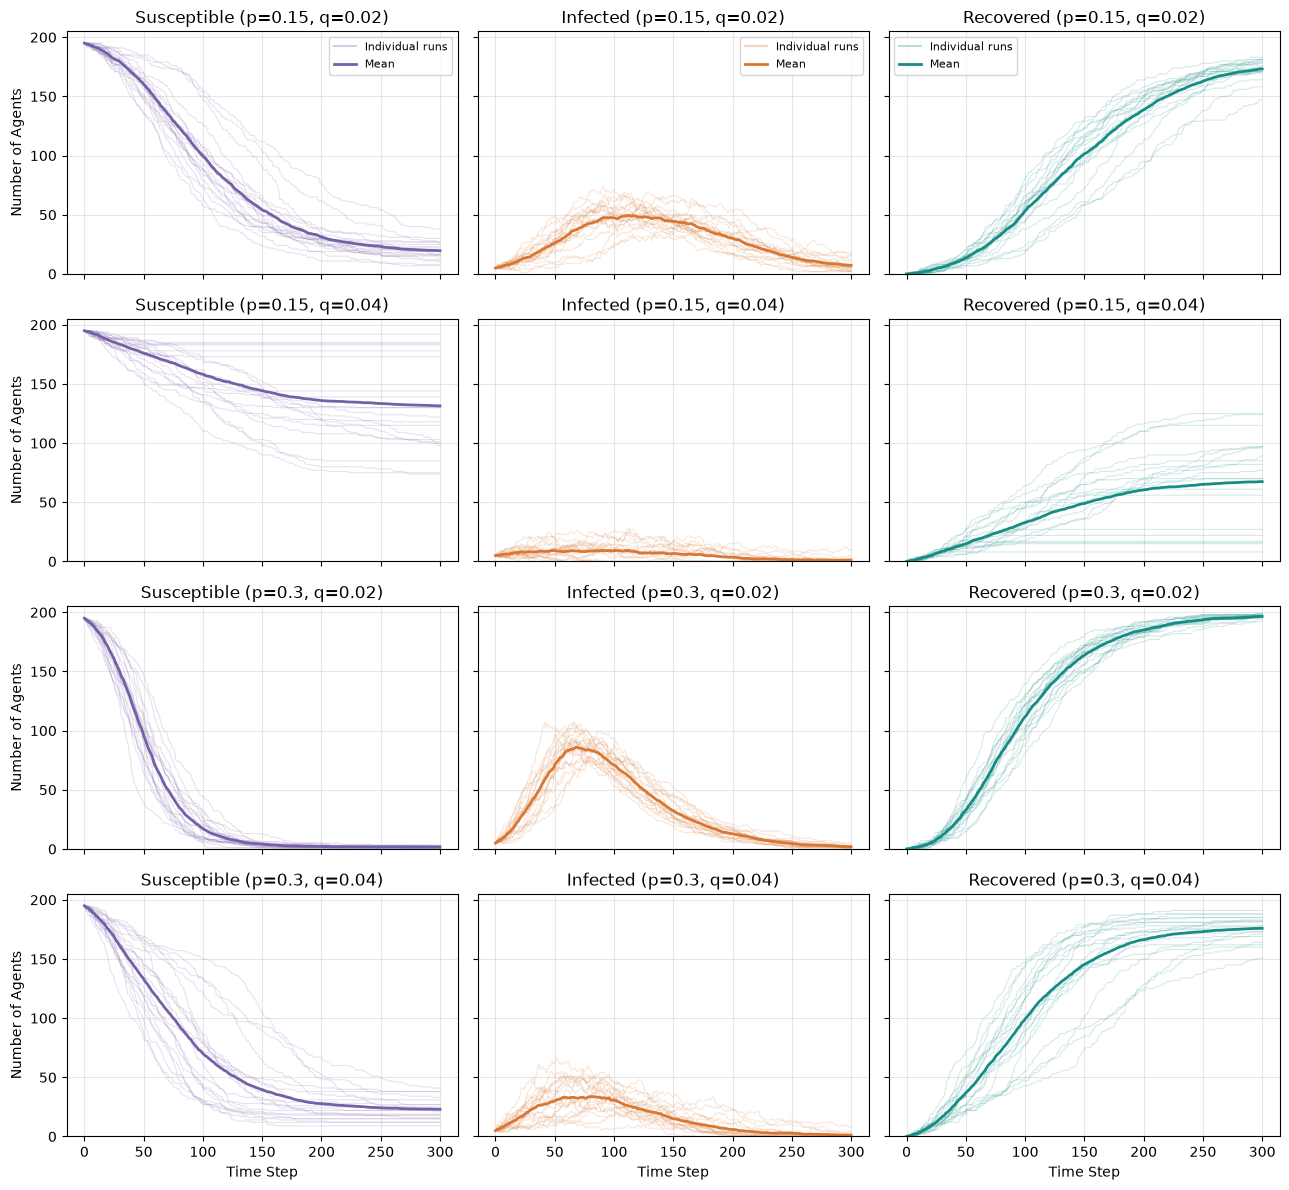

In [6]:
COLORS = ["#7560A8", "#D97732", "#168C85"]
LABELS = ["Susceptible", "Infected", "Recovered"]
time = np.arange(steps + 1)

fig, axes = plt.subplots(4, 3, figsize=(13, 12), sharex=True, sharey=True)
for row, (p_value, q_value) in enumerate(parameter_pairs):
    runs = sensitivity_runs[(p_value, q_value)]
    for state, (label, color) in enumerate(zip(LABELS, COLORS)):
        ax = axes[row, state]
        ax.plot(time, runs[:, :, state].T, color=color, alpha=0.18, linewidth=0.8)
        ax.plot([], [], color=color, alpha=0.3, label="Individual runs")
        ax.plot(time, runs[:, :, state].mean(axis=0), color=color,
                linewidth=2, label="Mean")
        ax.set_title(f"{label} (p={p_value}, q={q_value})")
        ax.set_ylim(0, 205)
        ax.grid(alpha=0.3)
        if state == 0:
            ax.set_ylabel("Number of Agents")
        if row == 3:
            ax.set_xlabel("Time Step")
        if row == 0:
            ax.legend(fontsize=8)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/part_a_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
from IPython.display import Markdown, display

rows = ["| p | q | Peak infected | Time to peak | Ever infected by 300 | Early extinction | Still infected at 300 |",
        "|---|---|---|---|---|---|---|"]
for (p_value, q_value), metrics in sensitivity_metrics.items():
    values = []
    for name in ["peak", "peak_time", "ever_infected"]:
        x = metrics[name]
        values.append(f"{x.mean():.1f} ± {x.std(ddof=1):.1f} ({x.min()}–{x.max()})")
    early = int(metrics["early_extinction"].sum())
    ongoing = int(metrics["ongoing"].sum())
    rows.append(f"| {p_value} | {q_value} | " + " | ".join(values)
                + f" | {early}/{n_runs} | {ongoing}/{n_runs} |")
display(Markdown("Values are **mean ± sample SD (range)** across 20 runs. "
                 "Peaks and first peak times are calculated separately for each run."
                 + chr(10) * 2 + chr(10).join(rows)))

Values are **mean ± sample SD (range)** across 20 runs. Peaks and first peak times are calculated separately for each run.

| p | q | Peak infected | Time to peak | Ever infected by 300 | Early extinction | Still infected at 300 |
|---|---|---|---|---|---|---|
| 0.15 | 0.02 | 58.9 ± 9.2 (38–74) | 120.4 ± 27.9 (77–174) | 180.4 ± 7.6 (163–193) | 0/20 | 20/20 |
| 0.15 | 0.04 | 17.2 ± 7.2 (5–28) | 68.8 ± 52.1 (0–168) | 68.5 ± 39.1 (8–126) | 1/20 | 6/20 |
| 0.3 | 0.02 | 93.8 ± 9.4 (78–107) | 71.0 ± 13.3 (42–94) | 198.4 ± 1.0 (197–200) | 0/20 | 19/20 |
| 0.3 | 0.04 | 44.5 ± 11.0 (25–67) | 86.8 ± 37.5 (29–183) | 177.0 ± 9.3 (159–191) | 0/20 | 7/20 |

**Analysis**

Increasing $p$ from 0.15 to 0.3 led to larger outbreaks. With $q=0.02$, the average peak went from 58.9 to 93.8 infected agents. With $q=0.04$, it went from 17.2 to 44.5. Increasing $q$ had the opposite effect. Both the peak and the total number infected were lower because agents recovered sooner. Peak timing was less predictable. A higher $p$ moved the average peak earlier at $q=0.02$, from step 120.4 to 71.0, but later at $q=0.04$, from 68.8 to 86.8.

The runs could look quite different even with the same parameters. For $p=0.15$ and $q=0.04$, the total number infected ranged from 8 to 126. Some outbreaks stayed small, but others spread through much of the population. The peaks also happened at different times. This made the average curve flatter, so I calculated each run’s peak before taking the average.

I counted early extinction as having no infected agents left by step 50. Only one run met this condition, in the $p=0.15$, $q=0.04$ group. None did in the other groups, though 20 runs is a small sample. Some runs in every group still had infections at step 300, so their final outbreak sizes could be larger than the totals reported here.

## B. Extending the Model: Social Distancing and Interventions

### i. Introduce social distancing measures with $p = 0.3$ and $q = 0.02$:

- Reduced movement: at each step, each agent moves only with probability $m$ (and otherwise stays in place). Which part of the model do you change to implement this?
- Avoidance: susceptible agents move away from cells occupied by infected agents whenever possible. Which part of the model do you change to implement this?
- For each measure, run at least 20 simulations of 300 steps and plot the average number of agents in each state over time.
- Which parameter controls the maximum number of simultaneously infected agents, which determines whether the healthcare system is overwhelmed?

In [8]:
# Check movement directly using small, controlled examples.
positions_test = np.array([[1, 1], [1, 1]])
states_test = np.array([SUSCEPTIBLE, INFECTED])
for seed_test in range(20):
    stationary = move_agents(positions_test, states_test, 3,
                            np.random.default_rng(seed_test),
                            np.random.default_rng(seed_test + 100), m=0)
    assert np.array_equal(stationary, positions_test)
    avoided = move_agents(positions_test, states_test, 3,
                         np.random.default_rng(seed_test),
                         np.random.default_rng(seed_test + 100), avoidance=True)
    assert not np.array_equal(avoided[0], [1, 1])
    assert np.all((avoided >= 0) & (avoided < 3))

blocked = move_agents(np.array([[0, 0], [0, 0]]), states_test, 1,
                      np.random.default_rng(1), np.random.default_rng(2),
                      avoidance=True)
assert np.all(blocked == 0)
assert np.array_equal(simulate_sir(seed=42),
                      simulate_sir(seed=42, m=1, avoidance=False))
print("Movement and avoidance checks passed.")

interventions = {
    "Baseline": {"m": 1.0, "avoidance": False},
    "Reduced movement (m=0.3)": {"m": 0.3, "avoidance": False},
    "Avoidance": {"m": 1.0, "avoidance": True},
}
intervention_runs = {}
for name, options in interventions.items():
    runs = np.array([
        simulate_sir(p=0.3, q=0.02, steps=300, seed=3000 + run, **options)
        for run in range(20)
    ])
    assert np.all(runs.sum(axis=2) == 200)
    assert np.all(np.diff(runs[:, :, SUSCEPTIBLE], axis=1) <= 0)
    assert np.all(np.diff(runs[:, :, RECOVERED], axis=1) >= 0)
    intervention_runs[name] = runs
    peaks = runs[:, :, INFECTED].max(axis=1)
    print(f"{name}: mean per-run peak = {peaks.mean():.1f}, "
          f"SD = {peaks.std(ddof=1):.1f} agents")

Movement and avoidance checks passed.
Baseline: mean per-run peak = 94.7, SD = 13.2 agents


Reduced movement (m=0.3): mean per-run peak = 49.7, SD = 10.4 agents


Avoidance: mean per-run peak = 79.2, SD = 11.8 agents


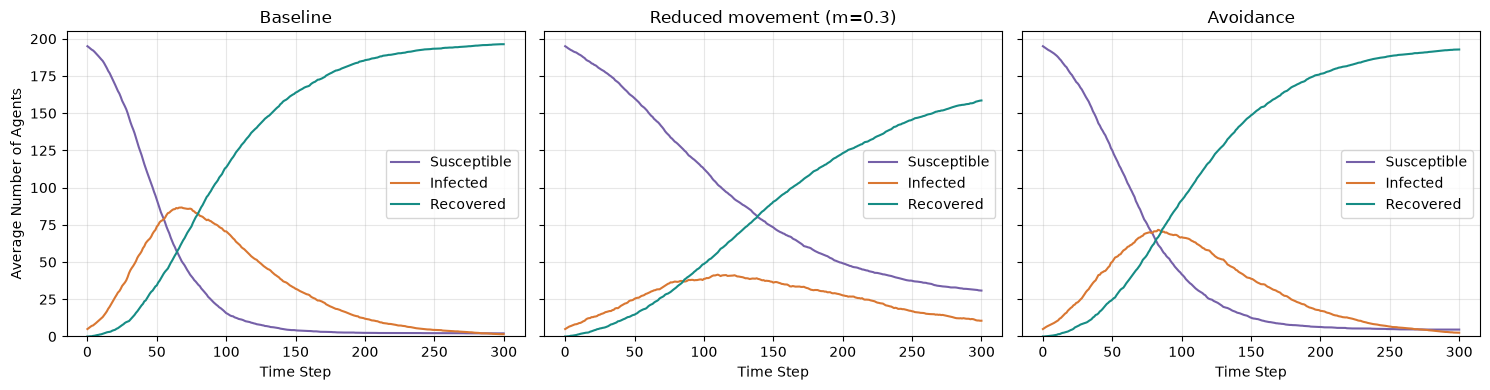

In [9]:
COLORS = ["#7560A8", "#D97732", "#168C85"]
LABELS = ["Susceptible", "Infected", "Recovered"]
time = np.arange(301)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, runs) in zip(axes, intervention_runs.items()):
    mean_counts = runs.mean(axis=0)
    for state, (label, color) in enumerate(zip(LABELS, COLORS)):
        ax.plot(time, mean_counts[:, state], color=color, label=label)
    ax.set_title(name)
    ax.set_xlabel("Time Step")
    ax.set_ylim(0, 205)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Average Number of Agents")
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/part_b_i_interventions.png", dpi=200, bbox_inches="tight")
plt.show()

**Analysis**

Both actions alter the movement patterns of agents. With $m=0.3$, agents possess a 30% probability of adhering to the original movement guideline. Alternatively, they remain stationary. Given that the regulation permits remaining, the probability of cell alteration is under 30%. Establishing $m=1$ reinstates the baseline.
Avoidance enables vulnerable agents to select a cell devoid of infected agents, predicated on their locations prior to travel. They remain if no secure cell is accessible. Infected agents retain the ability to enter their selected cells, hence interaction remains feasible.

Every method was evaluated through 20 iterations of 300 steps, utilizing $p=0.3$ and $q=0.02$. The tactics employed corresponded with the first placements. The mean peak per run was 94.7 agents for the baseline, 49.7 for diminished mobility, and 79.2 for evasion. Both strategies diminished the apex in these trials.

The variable $m$ governs motion, while $p$ and $q$ additionally influence the apex. A decrease in concurrent infections may alleviate strain on the healthcare system. The model does not account for hospital capacity, hence it cannot indicate if hospitals would be inundated.